In [ ]:
from collections import defaultdict
import re
from itertools import combinations, product
from typing import List
import os

import pandas as pd
from tqdm.notebook import tqdm
import numpy as np
import matplotlib.pyplot as plt
from transformers import BertTokenizer, BertModel
from transformers import AutoModel, AutoTokenizer

import torch
import torch.nn.functional as F
from scipy.spatial.distance import cosine

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


Notes:

- check intraquestion similarity > all other similarity
- tsne visulaization
- mover score
- hoeftings upper confident bound

In [ ]:
# @title convert questions.txt to .csv
def next_question(n, lines):
    while n < len(lines) and not lines[n].startswith("("):
        n += 1
    return n

if os.path.exists("questions.txt"):
    f = open("questions.txt", "r", encoding="utf-8")
    lines = f.readlines()
    f.close()

    questions_dict = {"subject": [], "type": [], "difficulty": [], "grade":[], "modifier": [], "question": []}
    n = next_question(0, lines)

    while n < len(lines):
        if not lines[n].startswith("("):
            print(f"Warning in line {n}, expected new question, got \"{lines[n]}\" instead")
            n = next_question(n, lines)
            continue

        args = []
        while True:
            args = re.findall(r'\(.*?\)|\w+', lines[n])
            if len(args) != 5:
                print(f"Warning in line {n}, expected five arguments, got \"{args}\" instead")
                args = re.findall(r'\(.*?\)|\w+', input())
            else:
                break

        questions_dict["subject"].append(args[0].strip("()"))
        questions_dict["type"].append(args[1].strip("()").split(", "))
        questions_dict["difficulty"].append(args[2].strip("()"))
        questions_dict["grade"].append(args[3].strip("()"))
        questions_dict["modifier"].append(args[4].strip("()").split(", "))
        n += 1

        question = ""
        while n < len(lines) and not (n+1 < len(lines) and lines[n].strip() == lines[n+1].strip() == ""):
            question += lines[n]
            n += 1
        questions_dict["question"].append(question)
        n += 2

    questions_df = pd.DataFrame(questions_dict)
    questions_df.to_csv("questions.csv", index = False)

In [ ]:
# @title similarity
class SemanticSimilarity:
    """
    A class for computing semantic similarity between texts using multiple transformer-based models.

    Supports Sentence-Transformers and BERT-style models with configurable pooling strategies,
    model weights, and power transforms to combine similarity scores.
    """

    def __init__(self,
                 models=[
                     "intfloat/multilingual-e5-large",
                     "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
                 ],
                 modes=None,
                 weights=None,
                 power_transform=None,
                 is_sentence_transformer=None,
                 device=None,
                 **kwargs
                 ) -> None:
        """
        Initialize the SemanticSimilarity object with one or more transformer models.

        Args:
            models (list): List of model names to load.
            modes (list or str): Pooling modes ("CLS" or "token_mean") for each model.
            weights (list): Weights to combine similarity scores from multiple models.
            power_transform (list): Exponents to apply to individual similarity scores before weighting.
            is_sentence_transformer (list): Whether each model is a Sentence-Transformer model.
            device (str or torch.device): Device to load models onto (e.g., "cuda" or "cpu").
            **kwargs: Additional unused keyword arguments.
        """
        self.models = {}
        self.tokenizers = {}

        if is_sentence_transformer is None:
            is_sentence_transformer = [m.lower().find("bert") == -1 for m in models]

        for model, is_st in zip(models, is_sentence_transformer):
            print(f"Loading {model}...")
            if is_st:
                self.tokenizers[model] = AutoTokenizer.from_pretrained(model)
                self.models[model] = AutoModel.from_pretrained(model)
                self.models[model].to(device)
            else:
                self.models[model] = BertModel.from_pretrained(model)
                self.tokenizers[model] = BertTokenizer.from_pretrained(model)
        self.model_is_st = dict(zip(models, is_sentence_transformer))

        if weights is None:
            weights = [1.0] * len(models)
        weights = np.array(weights) / sum(weights)
        self.weights = dict(zip(models, weights))

        if power_transform is None:
            power_transform = [1.0] * len(models)
        self.power_transform = dict(zip(models, power_transform))

        if modes is None:
            modes = "CLS"
        if isinstance(modes, str):
            modes = [modes] * len(models)
        self.modes = {model: mode.lower() for model, mode in zip(models, modes)}

        if device is None:
            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.device = device

    def _cosine_similarity(self, embedding1, embedding2):
        """
        Compute cosine similarity between two 1D embeddings.

        Args:
            embedding1 (np.ndarray): First embedding vector.
            embedding2 (np.ndarray): Second embedding vector.

        Returns:
            float: Cosine similarity between the two vectors.
        """
        if embedding1.ndim != 1 or embedding2.ndim != 1:
            raise ValueError(f"Both embeddings must be 1D (actual shapes {embedding1.shape} and {embedding2.shape})")
        return 1 - cosine(embedding1, embedding2)

    def _chunk_text(self, text, max_tokens, tokenizer):
        """
        Break a long text into chunks that fit within the model's token limit.

        Args:
            text (str): Input text.
            max_tokens (int): Maximum tokens per chunk.
            tokenizer: The tokenizer for the model.

        Returns:
            list: A list of tokenized chunks.
        """
        tokens = tokenizer.encode(text, add_special_tokens=False)
        return [tokens[i:i + max_tokens] for i in range(0, len(tokens), max_tokens)]

    def _mean_pooling(self, model_output, attention_mask):
        """
        Apply mean pooling over token embeddings with attention mask.

        Args:
            model_output (tuple): Output from transformer model.
            attention_mask (torch.Tensor): Mask to ignore padding tokens.

        Returns:
            torch.Tensor: Mean pooled sentence embedding.
        """
        token_embeddings = model_output[0]
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)

    def individual_embedding(self,
                             model,
                             text,
                             clean_latex=True,
                             max_length=512
                             ) -> np.ndarray:
        """
        Generate an embedding for a single piece of text using the specified model.

        Args:
            model (str): Model name to use for embedding.
            text (str): Input text.
            clean_latex (bool): Whether to clean LaTeX-like formatting from the text.
            max_length (int): Max length for BERT-style token chunking.

        Returns:
            np.ndarray: Normalized text embedding.
        """
        if self.model_is_st[model]:
            if clean_latex:
                text = self.clean_latex(text)
            encoded_input = self.tokenizers[model](text, padding=True, truncation=True, return_tensors='pt')
            encoded_input = {k: v.to(self.device) for k, v in encoded_input.items()}
            with torch.no_grad():
                model_output = self.models[model](**encoded_input)
            if self.modes[model] == "token_mean":
                doc_embedding = self._mean_pooling(model_output, encoded_input['attention_mask'])
            elif self.modes[model] == "cls":
                doc_embedding = model_output[0][:, 0, :]
            else:
                raise ValueError(f"Unknown mode {self.modes[model]}")
            doc_embedding = F.normalize(doc_embedding, p=2, dim=1).cpu().squeeze().numpy()
        else:
            chunks = self._chunk_text(text, max_length - 2, self.tokenizers[model])
            embeddings = []
            for chunk in chunks:
                input_ids = torch.tensor([self.tokenizers[model].build_inputs_with_special_tokens(chunk)])
                with torch.no_grad():
                    outputs = self.models[model](input_ids)
                if self.modes[model] == "token_mean":
                    embeddings.append(self._mean_pooling(outputs, input_ids.ne(self.tokenizers[model].pad_token_id)).numpy())
                elif self.modes[model] == "cls":
                    embeddings.append(outputs.last_hidden_state[:, 0, :].squeeze().numpy())
            doc_embedding = np.mean(embeddings, axis=0).squeeze()
        return doc_embedding

    def embeddings_dict(self, text, clean_latex=True):
        """
        Generate embeddings for a text using all configured models.

        Args:
            text (str): Input text.

        Returns:
            dict: Dictionary of model names and their respective embeddings.
        """
        embeddings = dict()
        for model in self.models.keys():
            embeddings[model] = self.individual_embedding(model, text, clean_latex)
        return embeddings

    def clean_latex(self, text):
        """
        Clean LaTeX-specific artifacts from text.

        Args:
            text (str): Raw text possibly containing LaTeX formatting.

        Returns:
            str: Cleaned text.
        """
        text = re.sub(r"\\[\w\*]*", "", text)
        text = re.sub(r"\{.*?\}", "", text)
        text = re.sub(r"\[.*?\]", "", text)
        return text.strip()

    def get_similarity(self,
                       in1: str | dict[str, np.ndarray],
                       in2: str | dict[str, np.ndarray],
                       power_transform=True
                       ):
        """
        Compute the weighted semantic similarity between two texts or embeddings.

        Args:
            in1 (str or dict): First input (text or precomputed embeddings).
            in2 (str or dict): Second input (text or precomputed embeddings).
            power_transform (bool): Whether to apply power transforms to similarity scores.

        Returns:
            float: Weighted similarity score between 0 and 1.
        """
        if isinstance(in1, str):
            in1 = self.clean_latex(in1)
        if isinstance(in2, str):
            in2 = self.clean_latex(in2)
        similarities = []
        for model in self.models.keys():
            if isinstance(in1, str):
                out1 = self.individual_embedding(model, in1)
            else:
                out1 = in1[model]
            if isinstance(in2, str):
                out2 = self.individual_embedding(model, in2)
            else:
                out2 = in2[model]
            similarity = self._cosine_similarity(out1, out2)
            if power_transform:
                similarity = similarity ** self.power_transform[model]
            similarity *= self.weights[model]
            similarities.append(similarity)

        similarities = np.array(similarities)
        assert similarities.sum() <= 1
        return similarities.sum()


# Experiment on manually selected data

In [ ]:
# @title science example

science_example = [
r"""Identify whether the changes listed below are reversible or irreversible.
\begin{enumerate}[label=\alph*.]
\item Melting ice
\item Burning wood
\item Boiling water
\item Rusting iron
\end{enumerate}""",

r"""Look at the examples below and classify them as reversible or irreversible. Write your answers.
Ice melting
Burning paper
Dissolving sugar in water
Cooking an egg""",

r"""Procedure:
Take a glass of water and add a teaspoon of salt. Stir it until the salt completely dissolves.
Observe: Can you see the salt?
To reverse the reaction: Leave the water to evaporate (or gently heat it). What happens to the salt?
Materials:
1 glass of water
1 teaspoon of salt
Spoon
Heat source (optional for evaporation)
""",

r"""Experiment: Ice vs. Burned Paper
Materials:
1 ice cube
1 small piece of paper
A bowl
Steps:
Place the ice cube in the bowl and let it melt. What happens? Can you freeze it again?
Carefully burn a small piece of paper (with an adult’s help). What happens to the paper? Can you make it paper again?
example""",

r"""Experiment: Balloon and Heat
Materials:
1 balloon
A bowl of warm water
A bowl of cold water
Steps:
Blow up the balloon and tie it.
Place the balloon in the bowl of warm water. Observe what happens.
Now place the balloon in the bowl of cold water. What happens this time?
Question: Why does the size of the balloon change with temperature?""",

r"""Which of these lists shows the correct order in which these things were invented?
\begin{enumerate}[label=\alph*.]
\item Car, horse and cart, aeroplane
\item Aeroplane, car, horse and cart
\item Horse and cart, aeroplane, car
\item Horse and cart, car, aeroplane
\end{enumerate}""",

r"""Underline the silent letter in each word
\begin{enumerate}
\item kneel knew knock knot
\item wrong wrap wreck wrist
\item numb thumb limb lamb
\item align reign design sign
\item chemist chorus choir chaos
\item young cousin touch country
\end{enumerate}"""]


Loading intfloat/multilingual-e5-large...


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

... (10 outputs left out)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

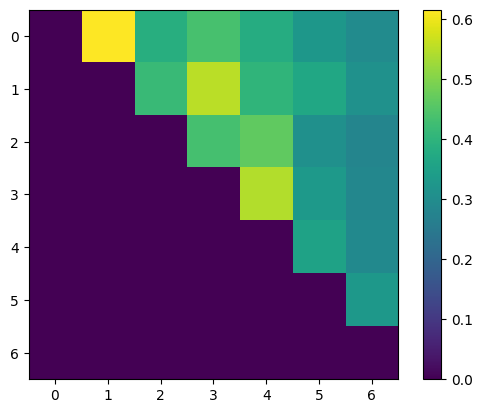

In [ ]:
# @title test SemanticSimilarity on small example [mean]

similarity = SemanticSimilarity(modes=["token_mean", "token_mean", "token_mean"], device=device)

embs = list()
similarities = np.zeros((len(science_example), len(science_example)))
min_sim = 1

# compute inter subject semantic similarity
for subject1, subject2 in combinations(range(len(science_example)), 2):
  similarities[subject1, subject2] = similarity.get_similarity(science_example[subject1], science_example[subject2])


plt.imshow(similarities)
plt.colorbar()
plt.show()

Loading intfloat/multilingual-e5-large...
Loading sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2...


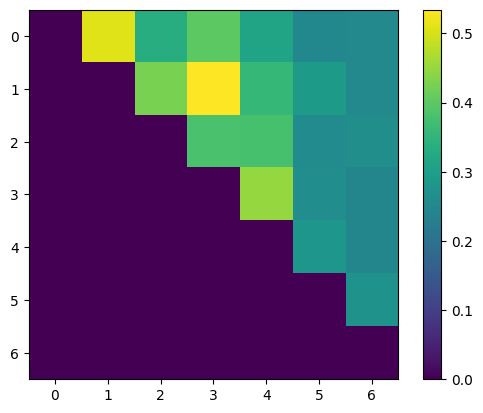

In [ ]:
# @title test SemanticSimilarity on small example [CLS]

similarity = SemanticSimilarity(weights=[0.4, 0.8], modes="CLS", device=device)

embs = list()
similarities = np.zeros((len(science_example), len(science_example)))
min_sim = 1

# compute inter subject semantic similarity
for subject1, subject2 in combinations(range(len(science_example)), 2):
  similarities[subject1, subject2] = similarity.get_similarity(science_example[subject1], science_example[subject2])


plt.imshow(similarities)
plt.colorbar()
plt.show()

In [ ]:
# Load data set
data = load_data("questions.csv")

subjects = [
            'English',
            'Dutch',
            'French',
            'Spanish',
            'German',
            'Geography',
            'History',
            'Social Studies',
            'Computer Science',
            'Science',
            'Mathematics'
            ]

assert all(s in data.subject.unique() for s in subjects)

# Experiment on questions dataset

In [ ]:
# @title load data

def next_question(n, lines):
    while n < len(lines) and not lines[n].startswith("("):
        n += 1
    return n


def load_data(path="questions.csv"):
  """
  Loads questions dataset into pandas dataframe.

  Args:
    path: str

  Returns: pandas dataframe with columns:
    subject: str
    type: List[str]
    difficulty: str
    grade: str
    modifier: List[str]
    question: str
  """
  # if there is a csv version, use it
  if path.split(".")[-1] == "csv":
    return pd.read_csv(path)

  f = open(path, "r", encoding="utf-8")
  lines = f.readlines()
  f.close()

  questions_dict = {"subject": [], "type": [], "difficulty": [], "grade":[], "modifier": [], "question": []}
  n = next_question(0, lines)

  while n < len(lines):
      if not lines[n].startswith("("):
          print(f"Warning in line {n}, expected new question, got \"{lines[n]}\" instead")
          n = next_question(n, lines)
          continue

      args = []
      while True:
          args = re.findall(r'\(.*?\)|\w+', lines[n])
          if len(args) != 5:
              print(f"Warning in line {n}, expected five arguments, got \"{args}\" instead")
              args = re.findall(r'\(.*?\)|\w+', input())
          else:
              break

      questions_dict["subject"].append(args[0].strip("()"))
      questions_dict["type"].append(args[1].strip("()").split(", "))
      questions_dict["difficulty"].append(args[2].strip("()"))
      questions_dict["grade"].append(args[3].strip("()"))
      questions_dict["modifier"].append(args[4].strip("()").split(", "))
      n += 1

      question = ""
      while n < len(lines) and not (n+1 < len(lines) and lines[n].strip() == lines[n+1].strip() == ""):
          question += lines[n]
          n += 1
      questions_dict["question"].append(question)
      n += 2

  questions_df = pd.DataFrame(questions_dict)
  questions_df.to_csv("questions.csv", index=False)
  return questions_df

In [ ]:
# @title test sentence transformer

# Compute similarity within and between subjects
def question_similarity(similarity, samples_per_subject, subjects):
  embeddings: dict[str, list] = defaultdict(list)
  similarities = np.zeros((len(subjects), len(subjects)))
  min_sim = 1
  for n, subject in tqdm(enumerate(subjects),
                        desc="Generating embeddings & Intrasubject similarity",
                        total=len(subjects), ):
    n_samples = min(samples_per_subject, len(data[data["subject"] == subject]))
    samples = data[data["subject"] == subject].sample(n=n_samples)
    embeddings[subject] = [similarity.embeddings_dict(q) for q in samples["question"]]
    # compute intra subject semantic similarity
    sim = []
    for embed1, embed2 in combinations(embeddings[subject], 2):
      sim_per_model = similarity.get_similarity(embed1, embed2)
      sim.append(sim_per_model)
    similarities[n, n] = np.mean(sim)
    assert similarities[n, n] <= 1
    if similarities[n, n] < min_sim:
      min_sim = similarities[n, n]

  # compute inter subject semantic similarity
  for subject1, subject2 in tqdm(combinations(subjects, 2),
                                desc="Intersubject similarity",
                                total=len(subjects) * (len(subjects) - 1) // 2,
                                ):
    ind1, ind2 = subjects.index(subject1), subjects.index(subject2)
    sim = []
    for embed1, embed2 in product(embeddings[subject1], embeddings[subject2]):
      sim_per_model = similarity.get_similarity(embed1, embed2)
      sim.append(sim_per_model)
    similarities[ind1, ind2] = np.mean(sim)
    assert similarities[ind1, ind2] <= 1
    if similarities[ind1, ind2] < min_sim:
      min_sim = similarities[ind1, ind2]

  plt.imshow(similarities, vmin=min_sim)
  plt.xticks(np.arange(len(subjects)), subjects, rotation=90)
  plt.yticks(np.arange(len(subjects)), subjects)
  plt.colorbar()
  plt.show()

In [ ]:
data = pd.read_csv("questions.csv")
subjects = [
            'English',
            'Dutch',
            'French',
            'Spanish',
            'German',
            'Geography',
            'History',
            'Social Studies',
            'Computer Science',
            'Science',
            'Mathematics'
]
assert all(s in data.subject.unique() for s in subjects)

In [ ]:
similarity = SemanticSimilarity(models=[
    "intfloat/multilingual-e5-large",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"],
                                weights=[0.4, 0.8],
                                power_transform=[4, 2],
                                modes="CLS",
                                device=device)

Loading intfloat/multilingual-e5-large...


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]

In [ ]:
embeddings = np.load("embeddings.npy", allow_pickle=True).item()
embedding_names = embeddings_df.columns
embeddings_df = pd.DataFrame(embeddings).transpose()
questions_df = pd.concat([data, embeddings_df], axis=1)

# Group by subject and calculate the mean embedding for each subject
mean_embeddings_per_subject = questions_df.groupby('subject')[embedding_names].mean()

# Iterate through each row of the DataFrame
for index, row in questions_df.iterrows():
    subject = row['subject']
    # Get the mean embedding for the subject
    mean_embedding = dict(mean_embeddings_per_subject.loc[subject])

    # Get the embedding for the current question
    current_embedding = dict(row[embedding_names])

    # Calculate cosine
    for embedding_name in embedding_names:
        dist = similarity._cosine_similarity(mean_embedding[embedding_name], current_embedding[embedding_name])
        questions_df.loc[index, embedding_name+"_dist"] = dist

    # Calculate the weighted score
    dist = similarity.get_similarity(mean_embedding, current_embedding)
    questions_df.loc[index, 'cosine_similarity_to_subject_mean'] = dist
questions_df.to_csv("questions_with_embeddings.csv", index=False)

NameError: name 'embeddings_df' is not defined

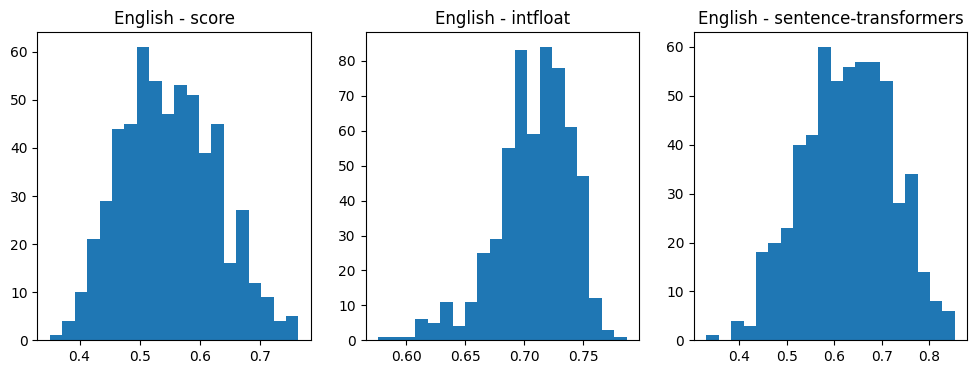

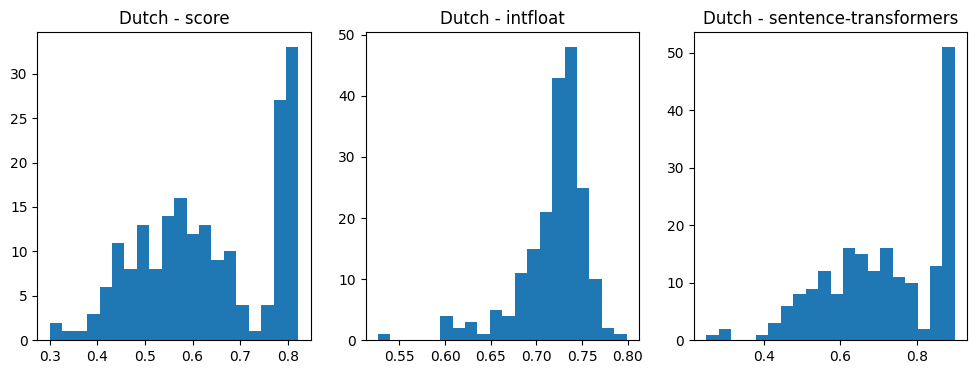

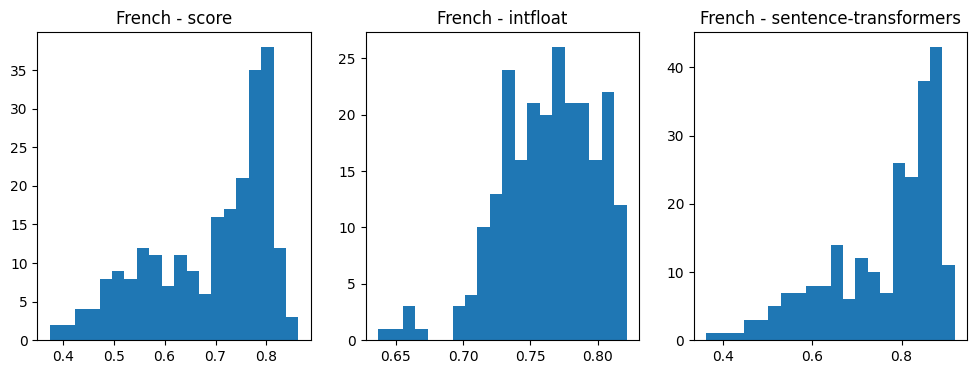

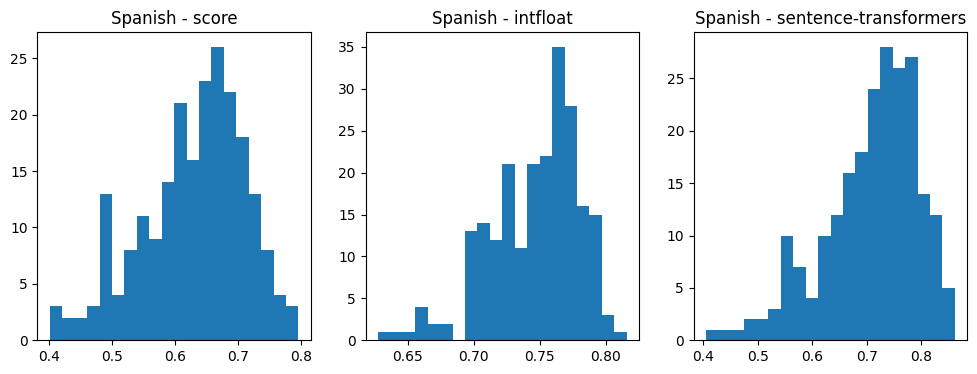

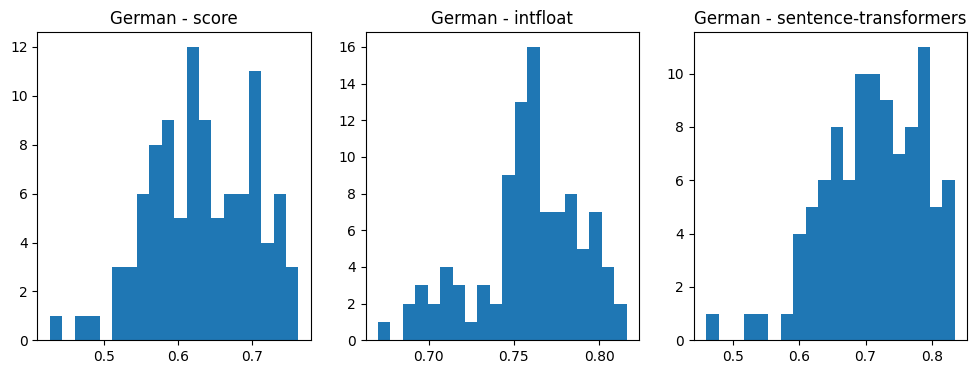

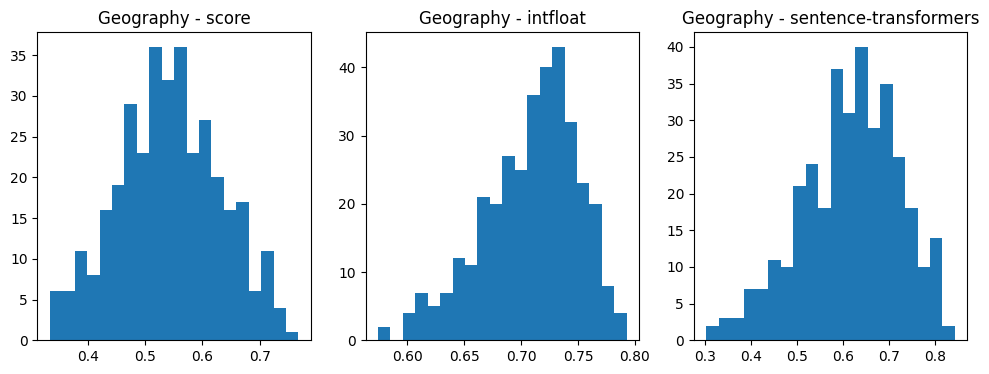

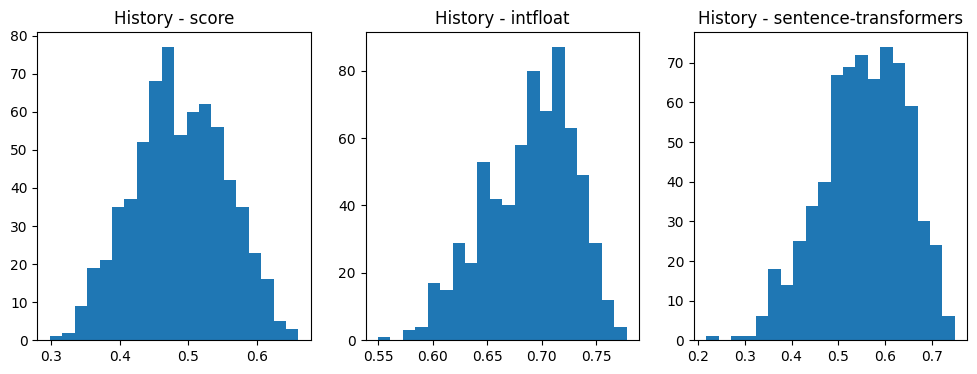

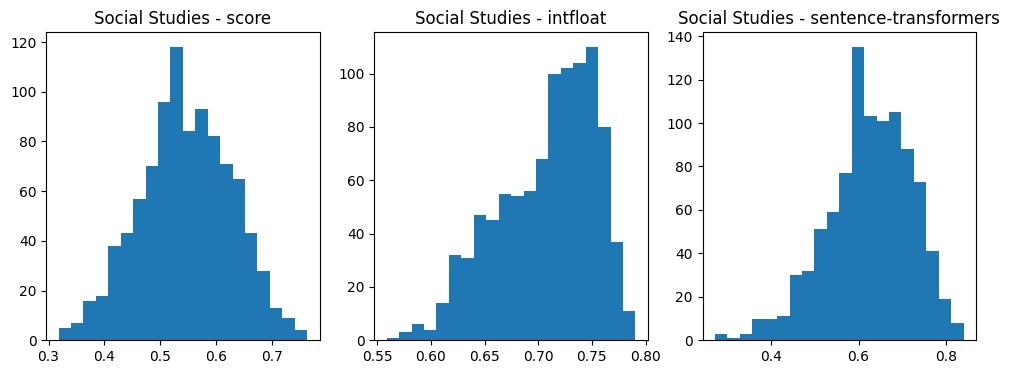

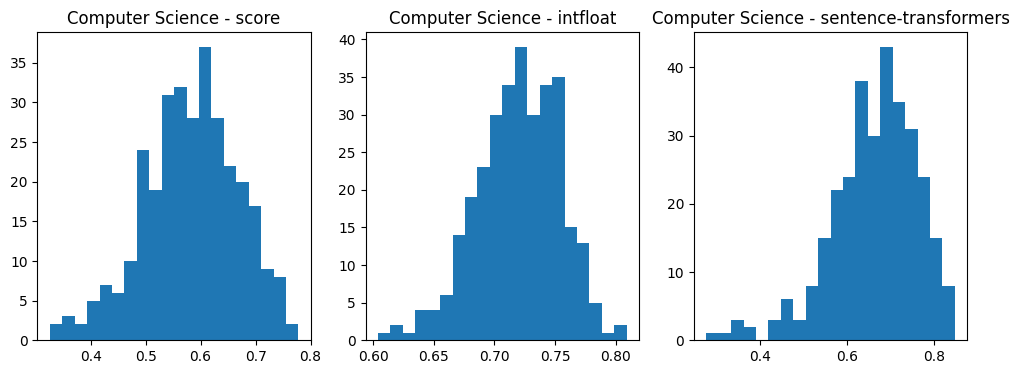

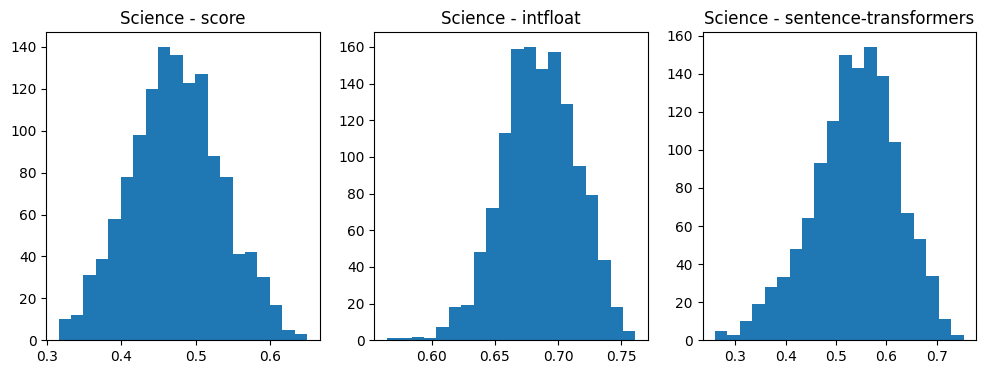

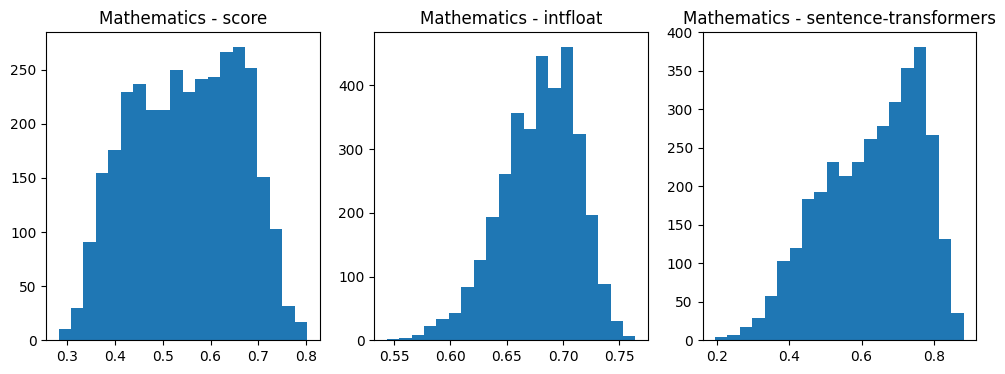

In [ ]:
for subject in subjects:
    fig, ax = plt.subplots(1, 1 + len(embedding_names), figsize=(12, 4))
    subject_data = questions_df[questions_df['subject'] == subject]
    ax[0].hist(subject_data['cosine_similarity_to_subject_mean'], bins=20)
    ax[0].set_title(subject + ' - score')
    for i, embedding_name in enumerate(embedding_names):
        scores = subject_data[embedding_name+'_dist']
        if embedding_name.split("/")[0] == "intfloat":
            scores = scores.apply(lambda x: x**4)
        ax[i+1].hist(scores, bins=20)
        ax[i+1].set_title(subject + ' - ' + embedding_name.split("/")[0])

In [ ]:
similarity = SemanticSimilarity(modes="CLS", device=device)

embeddings = {}
for i, row in tqdm(data.iterrows(), total=len(data)):
  embeddings[i] = similarity.embeddings_dict(row["question"])

np.save("embeddings.npy", embeddings)


Loading intfloat/multilingual-e5-large...
Loading sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2...


  0%|          | 0/8311 [00:00<?, ?it/s]

# Experiment: Visualize question embeddings

In [ ]:
import umap
import plotly.express as px
import numpy as np

# Assuming 'embeddings' is a dictionary where keys are question indices and values are dictionaries of model embeddings
# Example: embeddings = {0: {'model1': np.array([...]), 'model2': np.array([...])}, ...}
embeddings = np.load("embeddings.npy", allow_pickle=True).item()

# Choose a model to use for UMAP reduction
model_name = list(embeddings[0].keys())[1]  # Assuming all questions have embeddings for the same models

# Create a list of embeddings for all questions from the chosen model
all_embeddings = [embeddings[i][model_name] for i in embeddings]

# Reduce the dimensionality to 3 using UMAP
reducer = umap.UMAP(n_components=3, random_state=42)
reduced_embeddings = reducer.fit_transform(np.array(all_embeddings))

# Save reduced representation
np.save("reduced_embeddings.npy", reduced_embeddings)


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [ ]:
# Create a Plotly scatter plot
fig = px.scatter_3d(
    x=reduced_embeddings[:, 0],
    y=reduced_embeddings[:, 1],
    z=reduced_embeddings[:, 2],
    # Add question indices to hover data
    hover_data={"index": list(embeddings.keys())},
    color=data["subject"],
    color_discrete_sequence=px.colors.qualitative.Plotly,
    title="UMAP Visualization of Question Embeddings",
    width=1000,
    height=800
)


fig.show()

In [ ]:
anomalies = [
    [1631, 1637, 1680, 1687],
    [5546, 5553, 5555, 5605],
    [379, 1631, 1548, 1680, 5179]
]

for anomaly in anomalies:
  for i in anomaly:
    print(data.iloc[i]["question"])
    print("-"*100)
  print("=" * 100 + "\n\n")


The Maya recorded the actions and achievements of their kings on carved stone columns. The columns are called:  
\begin{enumerate}[label=\alph*.]
\item stelae  
\item stables  
\item shinto  
\end{enumerate}

----------------------------------------------------------------------------------------------------

How many calendars did the Maya use?  
\begin{enumerate}[label=\alph*.]
\item 1  
\item 2  
\item 3  
\end{enumerate}

----------------------------------------------------------------------------------------------------

The Maya were one of many civilisations of southern Mexico, Central America and South America. Use books and the Internet to research and prepare fact files about the Olmec, Inca and Aztec civilisations.

----------------------------------------------------------------------------------------------------

The Maya are believed to be the first people to discover how to make chocolate. Find out about the history of chocolate. How did the Maya enjoy chocolate? How d

In [ ]:
anomalies = [
  [2912, 2934, 2936],
  [2888, 2924, 2926],
  [3128, 3133],
  [3596, 3088, 3103, 3105]
]

for anomaly in anomalies:
  for i in anomaly:
    print(data.iloc[i]["question"])
    print("-"*100)
  print("=" * 100 + "\n\n")


All the letters of these words are jumbled up. Rearrange the letters so that they make meaningful words.
\begin{enumerate}
\item nadrb
\item alpk
\item alpk
\item ienoielrg
\item hrclilsvene
\end{enumerate}

\subsection*{Hints}

\begin{enumerate}
\item The answer starts with the letter \emph{b}\\
The meaning of this word (in English) :\\
\emph{fire}
\item The answer starts with the letter \emph{k}\\
The meaning of this word (in English) :\\
\emph{blow}
\item The answer starts with the letter \emph{k}\\
The meaning of this word (in English) :\\
\emph{blow}
\item The answer starts with the letter \emph{o}\\
The meaning of this word (in English) :\\
\emph{original}
\item The answer starts with the letter \emph{v}\\
The meaning of this word (in English) :\\
\emph{differ}
\end{enumerate}

\subsection*{Answers}
\begin{enumerate}
\item brand
\item klap
\item klap
\item origineel
\item verschillen
\end{enumerate}

-------------------------------------------------------------------------------

In [ ]:
similarity = SemanticSimilarity(models=[
    "intfloat/multilingual-e5-large",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"],
                                weights=[0.4, 0.8],
                                modes="cls",
                                device=device)

question_similarity(similarity, 200, subjects)

Loading intfloat/multilingual-e5-large...


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]

NameError: name 'question_similarity' is not defined

## paraphrase-multilingual-MiniLM-L12-v2

Loading intfloat/multilingual-e5-large...
Loading sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2...


Generating embeddings & Intrasubject similarity:   0%|          | 0/11 [00:00<?, ?it/s]

Intersubject similarity:   0%|          | 0/55 [00:00<?, ?it/s]

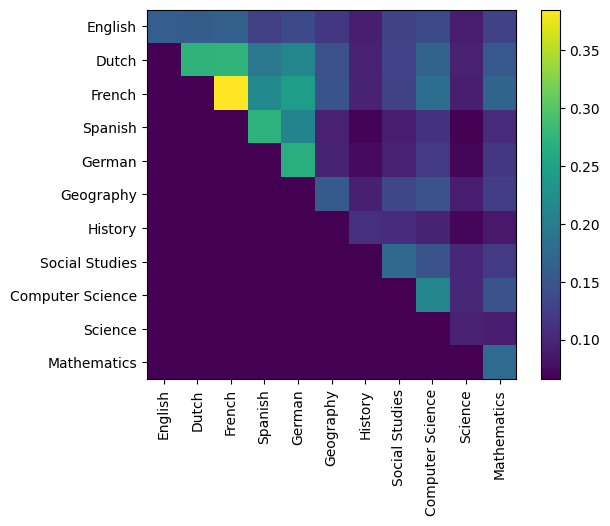

In [ ]:
similarity = SemanticSimilarity(models=[
    "intfloat/multilingual-e5-large",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"],
                                weights=[0, 1],
                                modes="CLS",
                                device=device)

question_similarity(similarity, 100, subjects)

Loading intfloat/multilingual-e5-large...
Loading sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2...


Generating embeddings & Intrasubject similarity:   0%|          | 0/11 [00:00<?, ?it/s]

Intersubject similarity:   0%|          | 0/55 [00:00<?, ?it/s]

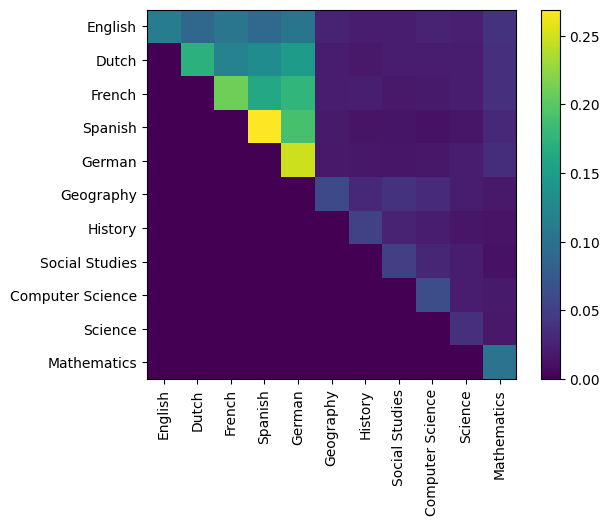

In [ ]:
similarity = SemanticSimilarity(models=[
    "intfloat/multilingual-e5-large",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"],
                                weights=[0, 1],
                                modes="token_mean",
                                device=device)

question_similarity(similarity, 100, subjects)

## multilingual-e5-large

Loading intfloat/multilingual-e5-large...
Loading sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2...


Generating embeddings & Intrasubject similarity:   0%|          | 0/11 [00:00<?, ?it/s]

Intersubject similarity:   0%|          | 0/55 [00:00<?, ?it/s]

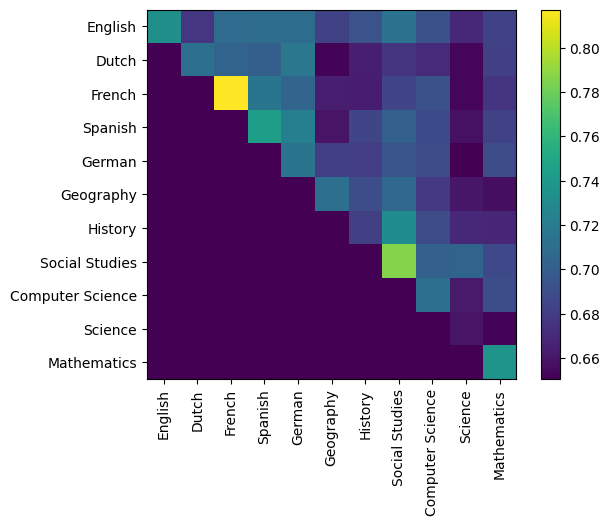

In [ ]:
similarity = SemanticSimilarity(models=[
    "intfloat/multilingual-e5-large",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"],
                                weights=[1, 0],
                                modes="CLS",
                                device=device)

question_similarity(similarity, 2, subjects)

Loading intfloat/multilingual-e5-large...
Loading sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2...


Generating embeddings & Intrasubject similarity:   0%|          | 0/11 [00:00<?, ?it/s]

Intersubject similarity:   0%|          | 0/55 [00:00<?, ?it/s]

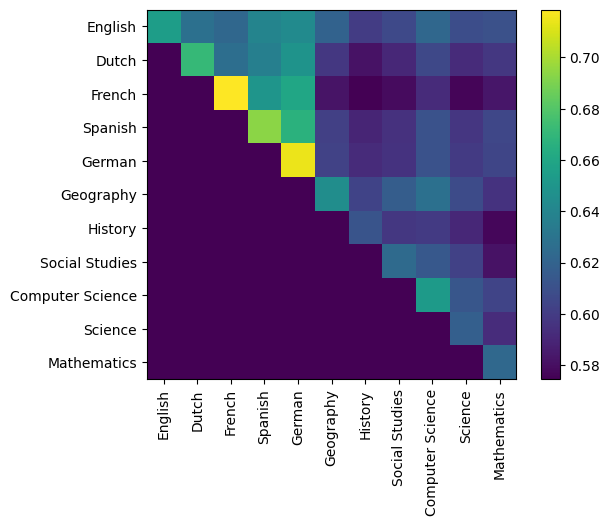

In [ ]:
similarity = SemanticSimilarity(models=[
    "intfloat/multilingual-e5-large",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"],
                                weights=[1, 0],
                                modes="token_mean",
                                device=device)

question_similarity(similarity, 100, subjects)